# Process B: variable overview and PCA

Read-only analysis of the calibration data (the input files are not modified).

* `calibration_data.csv`: 40 batches × 5001 time steps × 20 process variables
* `calibration_labels.csv`: one label per batch (accepted / rejected)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

DATA_DIR = "../input-data/Project 2 - BRPMM/process B/calibration data/"
df = pd.read_csv(DATA_DIR + "calibration_data.csv")
labels = pd.read_csv(DATA_DIR + "calibration_labels.csv").set_index("batch_id")["label"]

df["t"] = df.groupby("batch_id").cumcount()          # time step within each batch
VARS = [c for c in df.columns if c not in ("batch_id", "t")]
print(df.shape, "| batches:", df.batch_id.nunique(), "| steps per batch:", df.groupby("batch_id").size().unique())
print(labels.value_counts())

(200040, 22) | batches: 40 | steps per batch: [5001]
label
accepted    35
rejected     5
Name: count, dtype: int64


## 1. Each variable plotted separately
Each line is one batch over time. Grey = accepted, red = rejected.

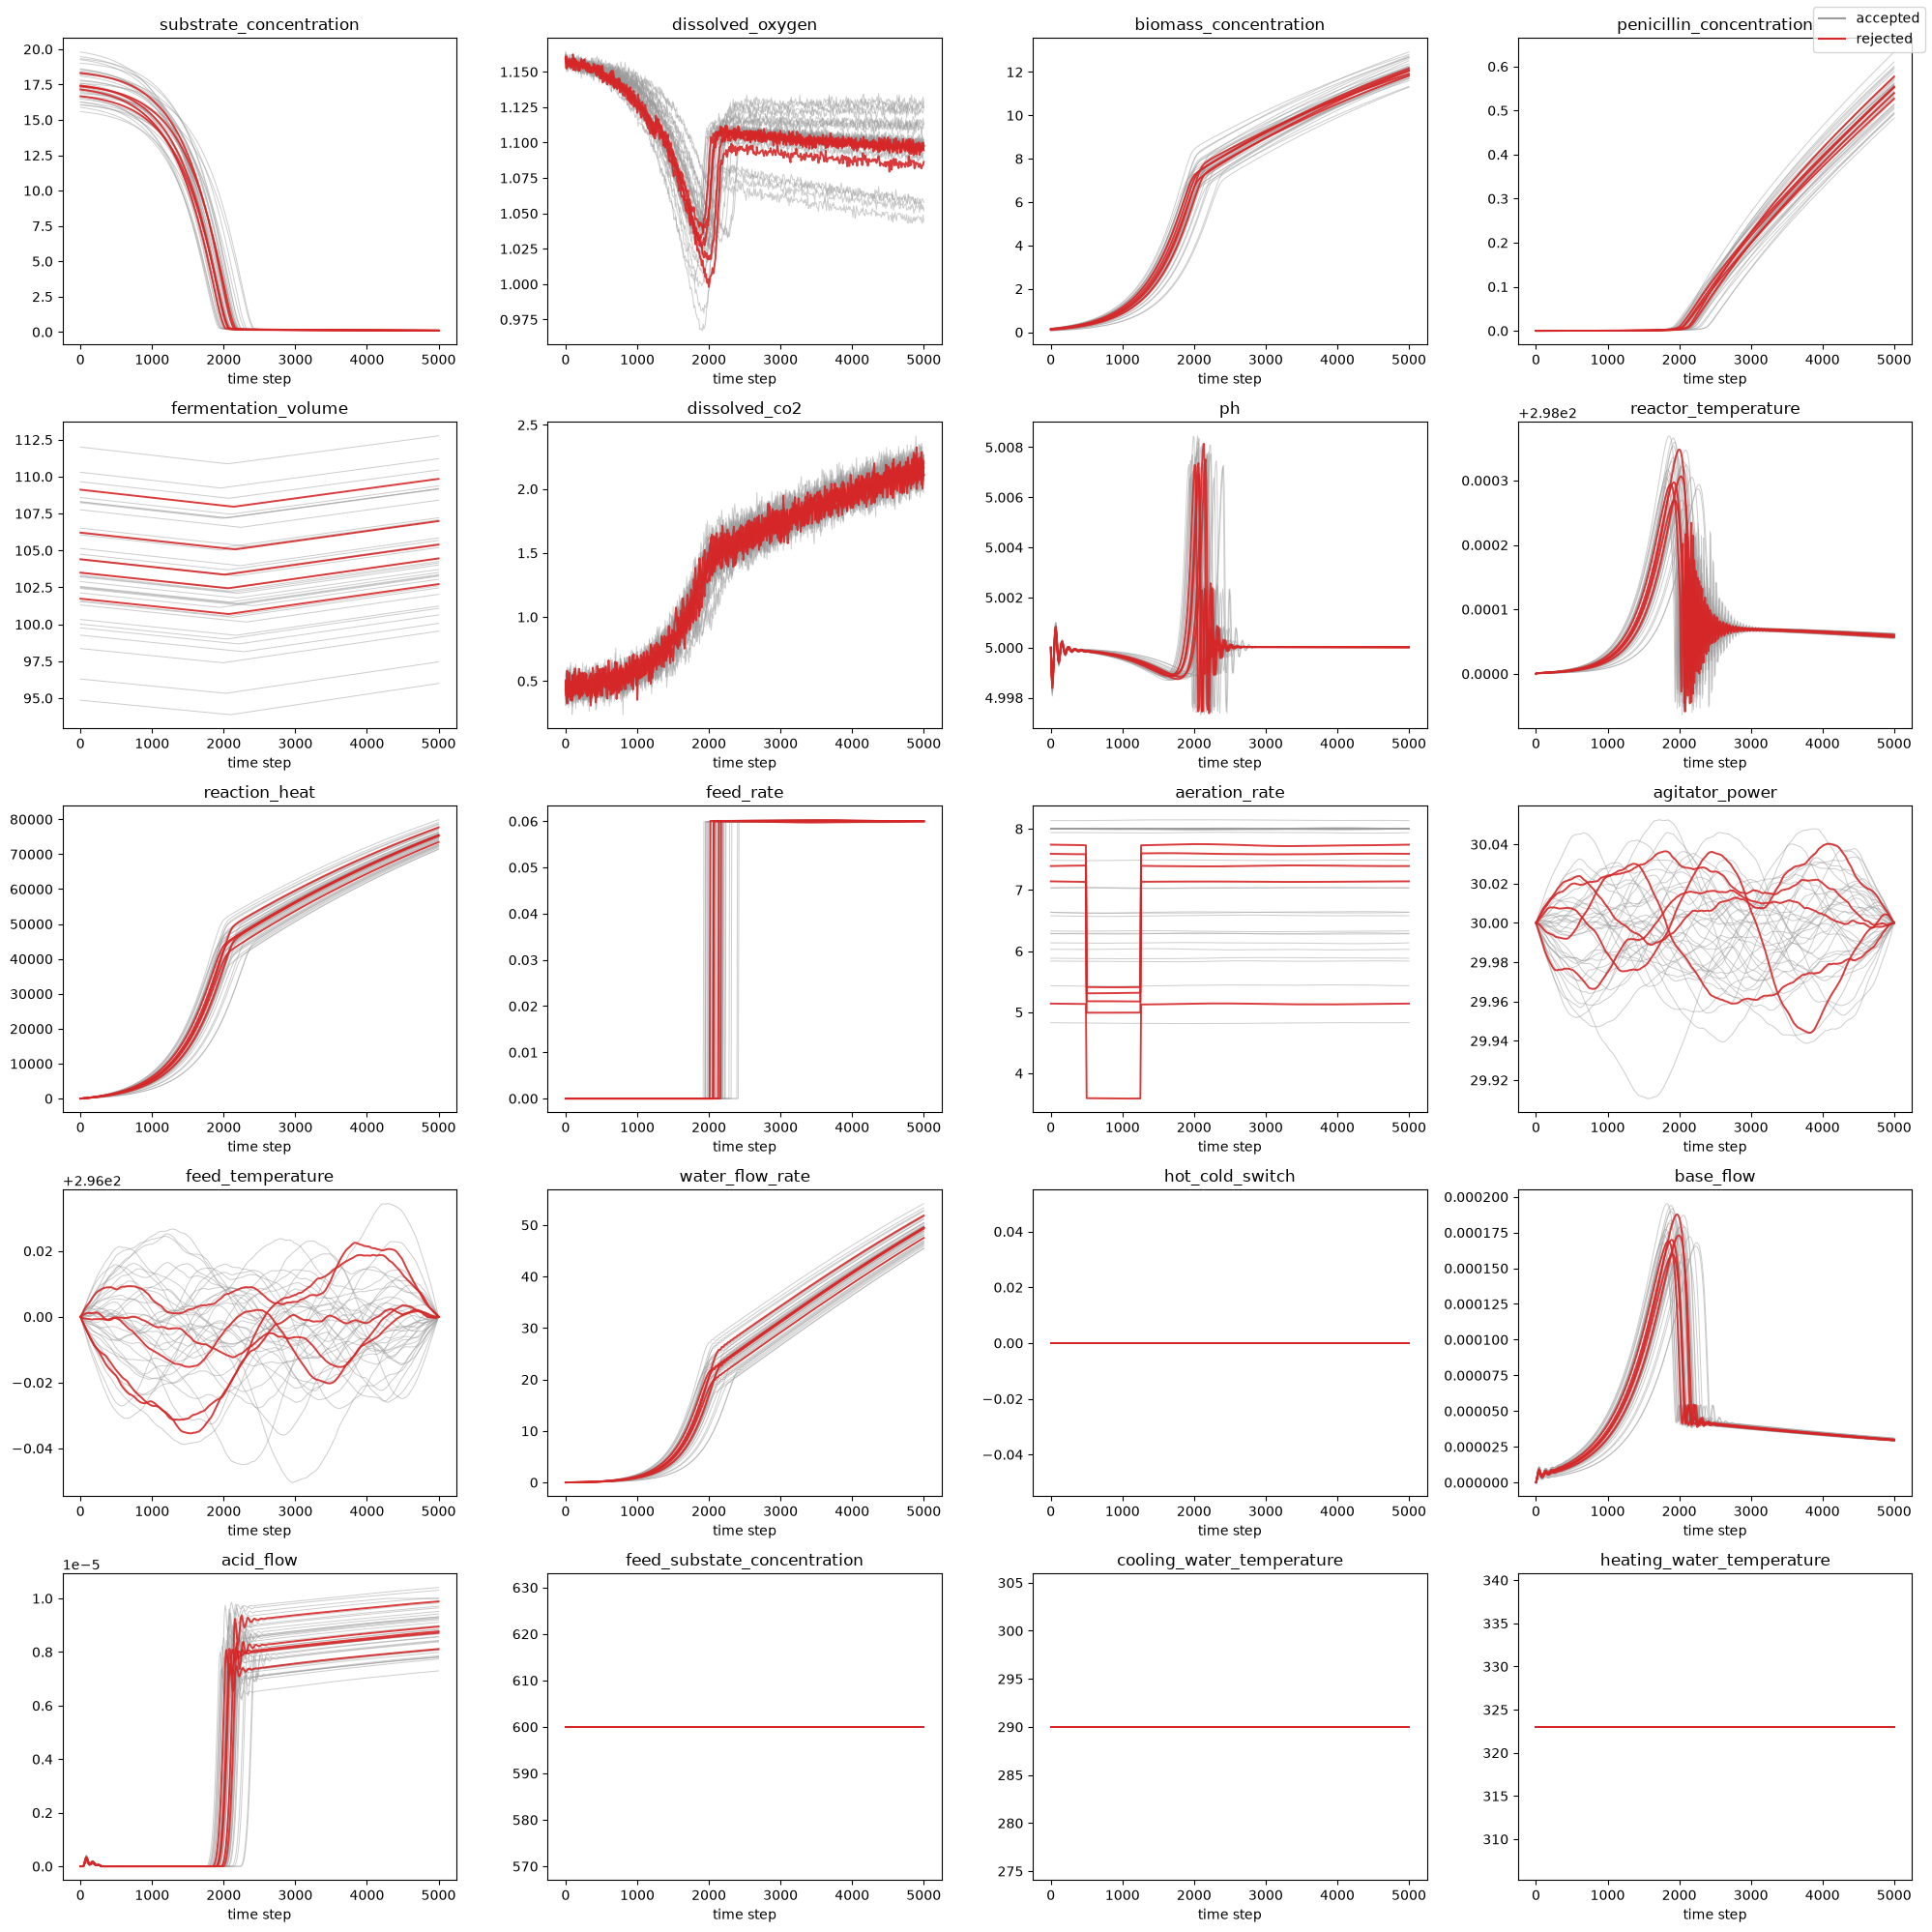

In [2]:
COLORS = {"accepted": "#9a9a9a", "rejected": "#d62728"}
step = 10  # plot every 10th time step to keep it fast

fig, axes = plt.subplots(5, 4, figsize=(20, 20))
for ax, var in zip(axes.flat, VARS):
    for bid, g in df.groupby("batch_id"):
        lab = labels[bid]
        ax.plot(g.t.values[::step], g[var].values[::step], color=COLORS[lab],
                lw=1.4 if lab == "rejected" else 0.7, alpha=0.9 if lab == "rejected" else 0.5,
                zorder=3 if lab == "rejected" else 2)
    ax.set_title(var); ax.set_xlabel("time step")
handles = [plt.Line2D([], [], color=c, label=l) for l, c in COLORS.items()]
fig.legend(handles=handles, loc="upper right")
fig.tight_layout()
plt.show()

Four variables never change (`hot_cold_switch`, `feed_substate_concentration`, `cooling_water_temperature`, `heating_water_temperature`), so they carry no information. They are removed before the PCA.

In [3]:
CONST = [v for v in VARS if df[v].std() < 1e-12]
FEATS = [v for v in VARS if v not in CONST]
print("constant:", CONST)
print(len(FEATS), "variables kept")

constant: ['hot_cold_switch', 'feed_substate_concentration', 'cooling_water_temperature', 'heating_water_temperature']
16 variables kept


## 2. PCA on the full trajectories (batch-wise unfolded / multiway PCA)

Each batch becomes one row containing every variable at 101 equally spaced time points (16 variables × 101 = 1616 columns). Each column is standardised, then PCA is fitted. This is the standard way to apply PCA to batch processes.

PCA is **unsupervised** (it never sees the labels), so for each component we check how well its score separates rejected from accepted batches (ROC AUC: 0.5 = no separation, 1.0 = perfect).

In [4]:
t_idx = np.linspace(0, 5000, 101).astype(int)
X_unf = df[df.t.isin(t_idx)].pivot(index="batch_id", columns="t", values=FEATS)   # columns = (variable, t)
y = (labels.loc[X_unf.index] == "rejected").astype(int).values
Xs = np.nan_to_num(StandardScaler().fit_transform(X_unf.values))

pca = PCA(n_components=10).fit(Xs)
scores = pca.transform(Xs)
auc = lambda s: max(roc_auc_score(y, s), 1 - roc_auc_score(y, s))
summary = pd.DataFrame({"explained_var": pca.explained_variance_ratio_.round(3),
                        "cum_explained": pca.explained_variance_ratio_.cumsum().round(3),
                        "AUC_vs_label": [round(auc(scores[:, k]), 3) for k in range(10)]},
                       index=[f"PC{k+1}" for k in range(10)])
summary

,explained_var,cum_explained,AUC_vs_label
PC1,0.430,0.430,0.560
PC2,0.130,0.560,0.514
PC3,0.093,0.653,0.589
PC4,0.076,0.729,0.720
PC5,0.042,0.771,0.594
PC6,0.031,0.802,0.703
PC7,0.023,0.825,0.571
PC8,0.020,0.845,0.771
PC9,0.018,0.863,0.646
PC10,0.016,0.879,0.531


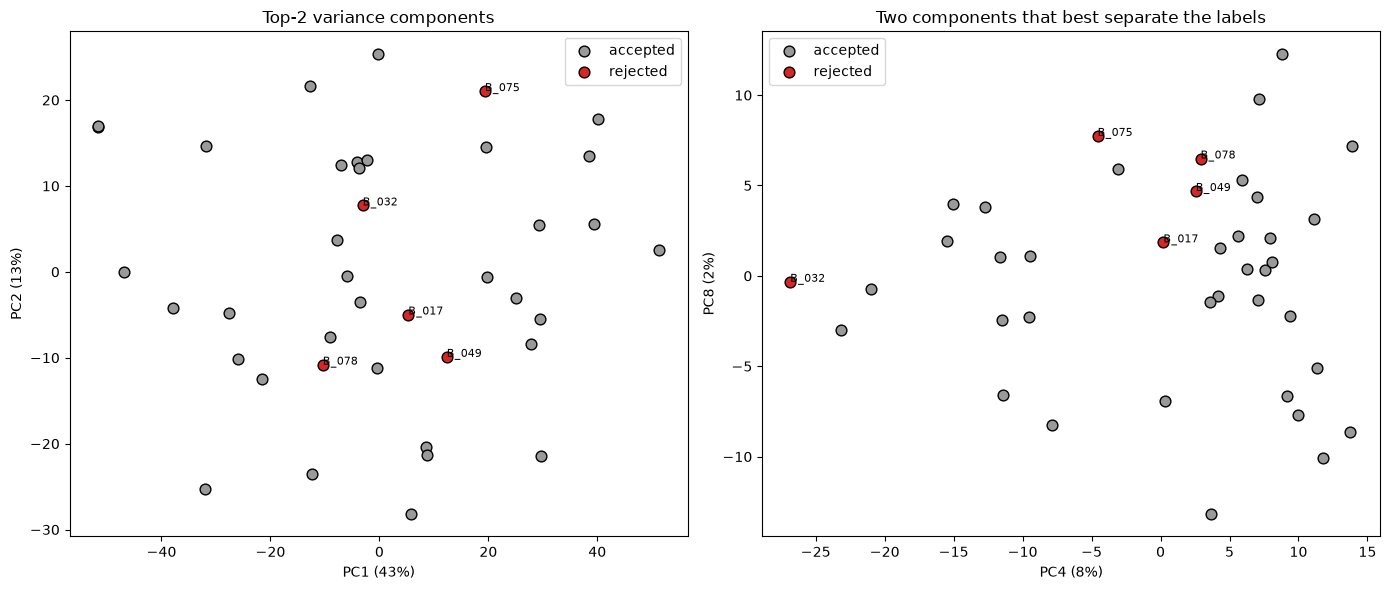

In [5]:
best = summary.AUC_vs_label.values.argsort()[::-1][:2]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (i, j) in zip(axes, [(0, 1), tuple(sorted(best))]):
    for lab, c in COLORS.items():
        m = labels.loc[X_unf.index].values == lab
        ax.scatter(scores[m, i], scores[m, j], c=c, label=lab, s=60, edgecolor="k")
    for k, bid in enumerate(X_unf.index):
        if y[k]: ax.annotate(bid, (scores[k, i], scores[k, j]), fontsize=8)
    ax.set_xlabel(f"PC{i+1} ({pca.explained_variance_ratio_[i]:.0%})")
    ax.set_ylabel(f"PC{j+1} ({pca.explained_variance_ratio_[j]:.0%})")
    ax.legend()
axes[0].set_title("Top-2 variance components"); axes[1].set_title("Two components that best separate the labels")
plt.tight_layout(); plt.show()

Each variable's contribution to a component is the sum of its squared loadings over all its time points. Each component's contributions add up to 1.

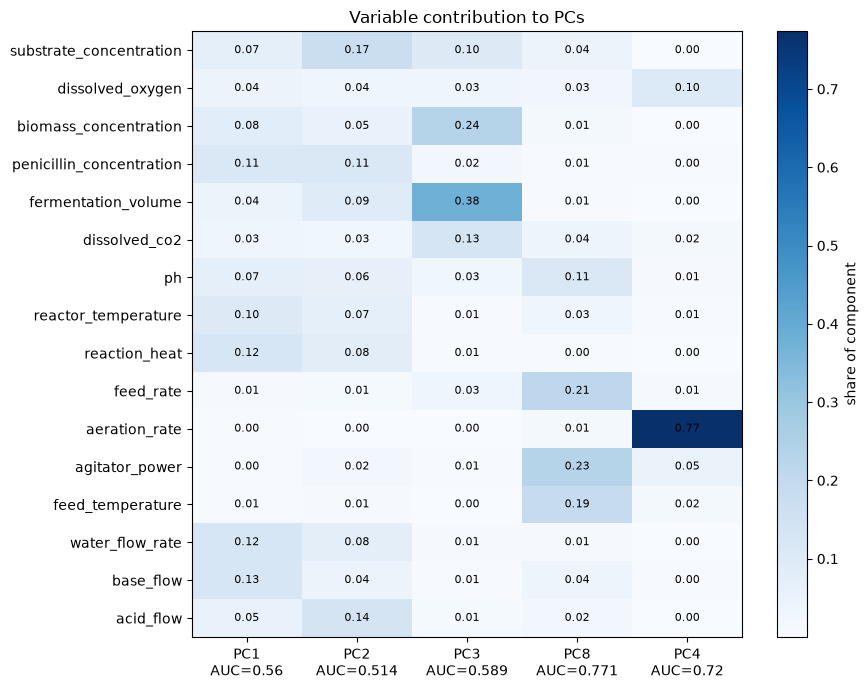

In [6]:
load = pd.DataFrame(pca.components_.T, index=X_unf.columns, columns=summary.index)
contrib = (load ** 2).groupby(level=0).sum().loc[FEATS]
show = ["PC1", "PC2", "PC3"] + [summary.index[k] for k in best if summary.index[k] not in ("PC1", "PC2", "PC3")]
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(contrib[show].values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(show)), [f"{p}\nAUC={summary.loc[p,'AUC_vs_label']}" for p in show])
ax.set_yticks(range(len(FEATS)), FEATS)
for r in range(len(FEATS)):
    for c in range(len(show)):
        ax.text(c, r, f"{contrib[show].values[r, c]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="share of component"); ax.set_title("Variable contribution to PCs")
plt.tight_layout(); plt.show()

## 3. PCA on per-batch summary features

The trajectories are dominated by the normal shape of the fermentation, so a short-lived anomaly gets a very small share of the variance. Here each variable is summarised per batch by its mean, standard deviation, min, max and final value, and PCA is fitted on those features.

In [7]:
summ = df.groupby("batch_id")[FEATS].agg(["mean", "std", "min", "max", "last"])
summ.columns = [f"{v}__{s}" for v, s in summ.columns]
summ = summ.loc[X_unf.index]
Zs = StandardScaler().fit_transform(summ.values)
pca2 = PCA(n_components=10).fit(Zs); sc2 = pca2.transform(Zs)
summary2 = pd.DataFrame({"explained_var": pca2.explained_variance_ratio_.round(3),
                         "AUC_vs_label": [round(auc(sc2[:, k]), 3) for k in range(10)]},
                        index=[f"PC{k+1}" for k in range(10)])
display(summary2)
k_best = summary2.AUC_vs_label.values.argmax()
ld = pd.Series(pca2.components_[k_best], index=summ.columns)
print(f"Top loadings of PC{k_best+1} (best separating component):")
ld.reindex(ld.abs().sort_values(ascending=False).index).head(10).round(3)

,explained_var,AUC_vs_label
PC1,0.450,0.537
PC2,0.153,0.589
PC3,0.123,0.600
PC4,0.074,0.720
PC5,0.041,0.543
PC6,0.036,0.714
PC7,0.024,0.971
PC8,0.022,0.851
PC9,0.018,0.663
PC10,0.015,0.526


Top loadings of PC7 (best separating component):


aeration_rate__std        0.540
aeration_rate__min       -0.344
dissolved_oxygen__last    0.338
dissolved_oxygen__mean    0.288
dissolved_oxygen__std    -0.286
feed_rate__max            0.259
feed_temperature__min     0.187
dissolved_oxygen__min     0.170
feed_temperature__mean    0.165
dissolved_co2__last      -0.159
dtype: float64

## 4. Direct check: how well does each variable separate the labels on its own?

PCA ranks variables by how much **variance** they explain, which is not the same as how useful they are for **predicting the label**. As a supervised sanity check, the table below gives the ROC AUC of each single summary feature against the label.

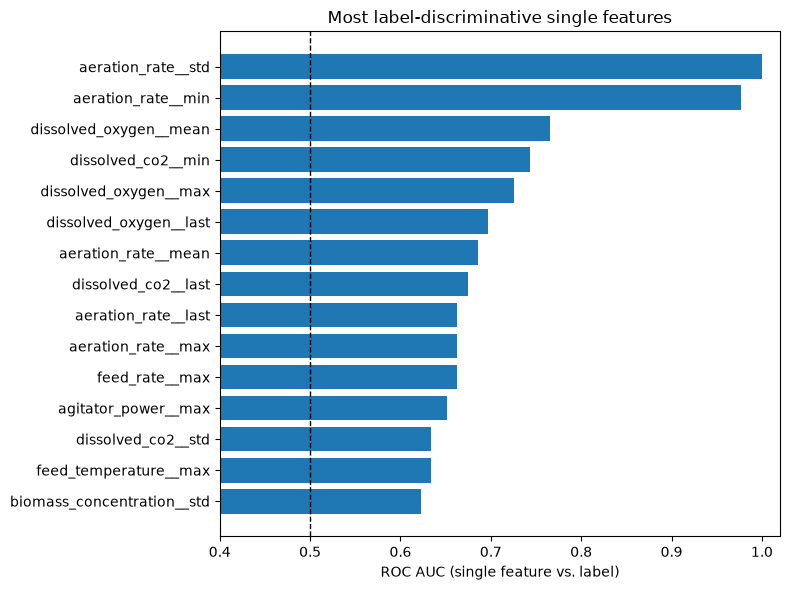

aeration_rate__std            1.000
aeration_rate__min            0.977
dissolved_oxygen__mean        0.766
dissolved_co2__min            0.743
dissolved_oxygen__max         0.726
dissolved_oxygen__last        0.697
aeration_rate__mean           0.686
dissolved_co2__last           0.674
aeration_rate__last           0.663
aeration_rate__max            0.663
feed_rate__max                0.663
agitator_power__max           0.651
dissolved_co2__std            0.634
feed_temperature__max         0.634
biomass_concentration__std    0.623
dtype: float64

In [8]:
uni = pd.Series({c: auc(summ[c].values) for c in summ.columns}).sort_values(ascending=False)
top = uni.head(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index[::-1], top.values[::-1], color="#1f77b4"); ax.axvline(0.5, color="k", ls="--", lw=1)
ax.set_xlabel("ROC AUC (single feature vs. label)"); ax.set_xlim(0.4, 1.02)
ax.set_title("Most label-discriminative single features")
plt.tight_layout(); plt.show()
top.round(3)

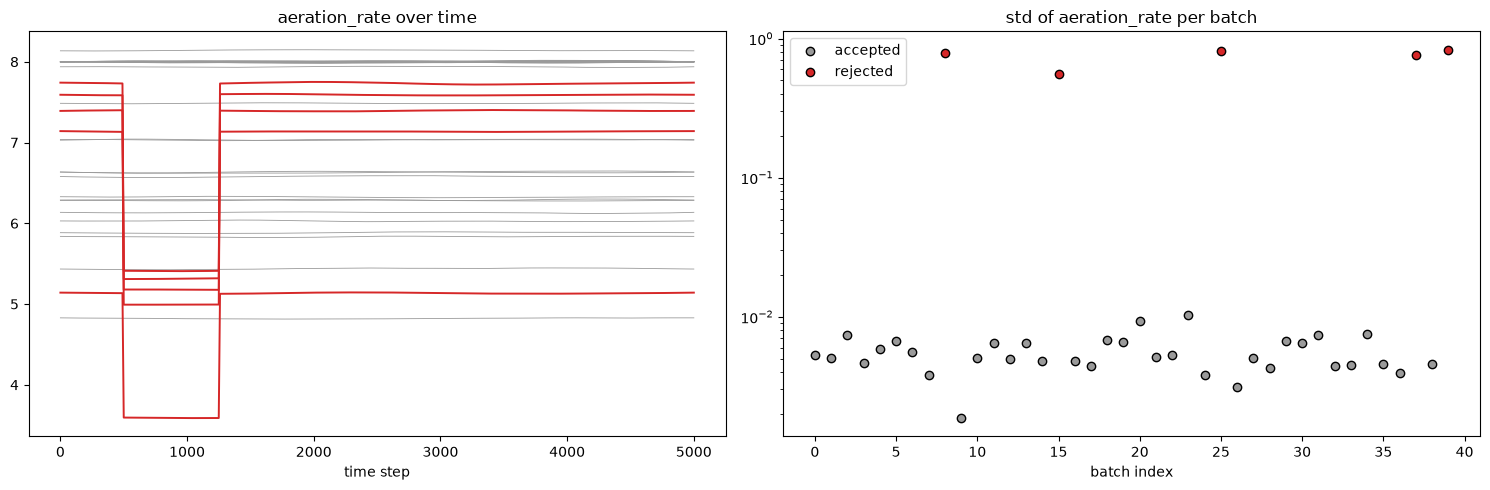

          aeration_rate__std     label
batch_id                              
B_066               0.007550  accepted
B_039               0.009259  accepted
B_045               0.010272  accepted
B_032               0.552171  rejected
B_075               0.765821  rejected
B_017               0.791482  rejected
B_049               0.813697  rejected
B_078               0.830575  rejected


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for bid, g in df.groupby("batch_id"):
    lab = labels[bid]
    axes[0].plot(g.t[::step], g.aeration_rate[::step], color=COLORS[lab], lw=1.4 if lab == "rejected" else 0.6, zorder=3 if lab == "rejected" else 2)
axes[0].set_title("aeration_rate over time"); axes[0].set_xlabel("time step")
s = summ["aeration_rate__std"]
for lab, c in COLORS.items():
    m = labels.loc[s.index] == lab
    axes[1].scatter(np.where(m)[0], s[m], c=c, label=lab, edgecolor="k")
axes[1].set_yscale("log"); axes[1].set_title("std of aeration_rate per batch"); axes[1].set_xlabel("batch index"); axes[1].legend()
plt.tight_layout(); plt.show()
print(pd.concat([s, labels], axis=1, join="inner").sort_values("aeration_rate__std").tail(8))

## Conclusion

* **`aeration_rate` is the most useful variable for the label.** All 5 rejected batches have a temporary drop in aeration between roughly time steps 500 and 1250. No accepted batch has one. Its per-batch standard deviation separates the two classes perfectly (AUC = 1.0): it is about 0.55–0.83 for rejected batches and at most 0.01 for accepted ones.
* **The main PCA components don't capture this.** PC1–PC3 of the trajectory PCA (65% of the variance) mostly describe the normal fermentation curve (heat, water flow, base flow, penicillin, volume, biomass) and barely separate the labels (AUC 0.51–0.59). PC4 is 77% `aeration_rate`, but it mostly reflects the different aeration *setpoints* between batches, so it only reaches AUC 0.72.
* In the summary-feature PCA, the best-separating component is PC7 (AUC 0.97, only 2.4% of the variance). Its loadings are dominated by `aeration_rate__std` / `__min`, followed by `dissolved_oxygen`.
* Next most informative: `dissolved_oxygen` (AUC ~0.77) and `dissolved_co2` (~0.74), which react to the aeration drop. Four variables are constant and carry no information.
* Caveat: there are only 5 rejected batches, so any rule beyond the aeration-drop signal should be checked carefully.